In [70]:
import numpy as np
import pandas as pd
from scipy import optimize
from scipy import stats
# Turn on a setting to use Pandas more safely.
# We will discuss this setting ®later.
pd.set_option('mode.chained_assignment', 'raise')

# Also - set up plotting
import matplotlib.pyplot as plt
%matplotlib inline
plt.style.use('fivethirtyeight')

### Outline - 
### Permutation for slopes
- Solution to the permutation for slopes problem
### Analyzing count data
- Analyzing count data
  - Usually - Tables of data from different _categories_
    - categories: e.g. survived/died
    - first class/third class passengers
    - women/men
    - disease/no disease
- Question:  Does one category change the outcome in the other category
  - Does gender change the likelihood of disease?
  - Does SES change the incidence of depression?
- How can we answer these kinds of questions with our usual tools?
  - Permutation testing for count data

## Count data

- Occurs when there are counts in 2 or more categories
  - e.g.
  - Is colon cancer more common in men than women?
    - categories:  men/women  ||  colon cancer/no colon cancer
  - Is warming in artic regions happening faster than in temperate regions
    - Count days that are 10 degrees above the seasonal year 2000 average
    - categories:    arctic region/temperate region  ||     >10 degrees above average/<10 degrees above average
    - (counts extreme days)
  - Is depression more common among people who are unemployed
    - categories:  employed/unemployed  ||   depression/no depression
   

### Not count data
- Has the temperature in artic regions changed more than in temperate regions?
  - Compare the year 1995-2000 daily average high temperatures to 2026
  - categories:   arctic/non-arctic
  - BUT the temperature is not a category - **degrees** above the 1995-2000 average
    - It is a mean.  Use our techniques for comparing means (mosquitoes and beer)
   
<br>

- Is the depression index higher for people on lower incomes?
  - Relationship between depression and income
  - **Neither** is a category
  - Depression index score (e.g. 0-100)
  - Income
  - This is a question about linear relationships
    - Does the depression index go up as income goes down?


### Python functions

`[data frame column].value_counts()`
- returns counts for each _type_ of in the dataframe column

`pd.crosstab(df[column],df[column])`
- returns a table of counts for the crossed categories in the columns
  - e.g. died/survived
  - first class/third class

The crostabulation table has counts for 
- first class/died
- first class/survived
- third class/died
- third class/survived

- crossing: put each level of category 1 against all the levels of category 2

`np.repeat([label1, label2...],[count1, count2])`
- makes a column/array of data
- repeats label1 count1 times
- repeates label2 count2 times

## Our question: Who survived on the titanic?
### Did it matter which class you were in?

<img src="Titanic.png" align = left>
<img src="Titanic_wreck.png" aligh = right>

### Read raw data
- Passenger list
  - Name, gender, age, relatives, fare
  - Who survived: survived = 1, died = 0
  - Pclass is the passenger class (1st, 2nd, 3rd)

In [71]:
titanic_data = pd.read_csv("titanic.csv")
titanic_data.head()

,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [72]:
titanic_data["Sex"].value_counts()

Sex
male      573
female    314
Name: count, dtype: int64

In [73]:
titanic_data["Pclass"].value_counts()

Pclass
3    487
1    216
2    184
Name: count, dtype: int64

### Making a summary table - who died/survived by passenger class
#### This is a 'cross tabulation table' or 'crosstabs table'
- Frequently data that you download is already in summary format this table is what you download

In [74]:
survival_table = pd.crosstab(titanic_data["Survived"],titanic_data["Pclass"])
survival_table = survival_table.rename(columns={1:"first",2:"second",3:"third"})
survival_table

Pclass,first,second,third
Survived,,,
0,80,97,368
1,136,87,119


## tidying up

I just want to compare first and third class  

How do I drop second class?

In [75]:
# choose the columns you want to keep (by name)
survival_1_3 = survival_table[["first","third"]].copy()
survival_1_3

Pclass,first,third
Survived,,
0,80,368
1,136,119


In [76]:
# Another way - use 'drop' and list the columns you **don't** want
# choose the columns you want to drop
survival_1_3 = survival_table.drop(["second"],axis=1).copy() # note brackets around 'second' 
                                                       # -- you might want to drop more than one column
survival_1_3

Pclass,first,third
Survived,,
0,80,368
1,136,119


### Rename rows so you know what 0 and 1 mean

In [77]:
# rename rows (the 'index' of the data frame)
survival_1_3.rename(index={0:"died",1:"survived"},inplace=True)
# inplace = True means make this change in the existing survival_1_3 data frame
survival_1_3

Pclass,first,third
Survived,,
died,80,368
survived,136,119


### Let's visualize that result (\*\*restart here\*\* for later exercise)

It will probably be clearest if we present percentages

In [78]:
# make a table of percentages

percent_survival=pd.DataFrame()
percent_survival["first"] = survival_1_3["first"]/np.sum(survival_1_3["first"])
# 'sum' adds up over 'died' and 'survived' for first class
percent_survival["third"] = survival_1_3["third"]/np.sum(survival_1_3["third"])
# 'sum' adds 
percent_survival

,first,third
Survived,,
died,0.37037,0.755647
survived,0.62963,0.244353


In [79]:
survival_1_3["first"]

Survived
died         80
survived    136
Name: first, dtype: int64

In [80]:
np.sum(survival_1_3["first"])

np.int64(216)

In [81]:
survival_1_3["first"]/np.sum(survival_1_3["first"])

Survived
died        0.37037
survived    0.62963
Name: first, dtype: float64

### plot just the % survived to compare

In [82]:
survived_percentages=percent_survival.loc["survived"]
# save only the 'survived' values
survived_percentages

first    0.629630
third    0.244353
Name: survived, dtype: float64

Text(0.5, 1.0, 'Class of Titanic survivors')

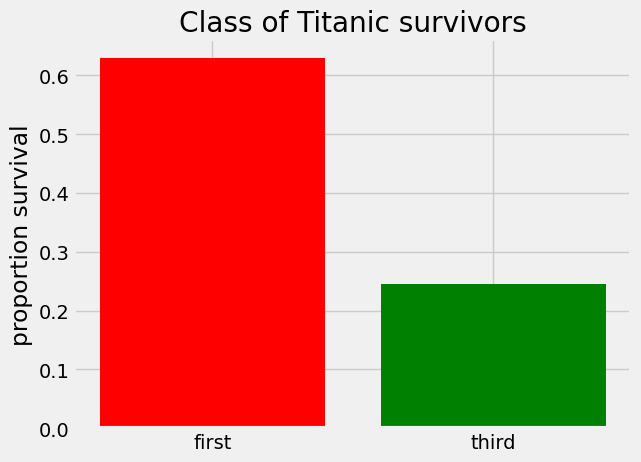

In [83]:
plt.bar(["first","third"],height=survived_percentages,color=["red","green"])
plt.ylabel("proportion survival")
plt.title("Class of Titanic survivors")

In [84]:
survived_percentages

first    0.629630
third    0.244353
Name: survived, dtype: float64

### Looks like first class passengers survived more often.  Was that difference real?
- How can we test that?
- Our usual tool - simulating a 'no difference' world/permutation test

### Logic - like mosquitoes and beer
- If class doesn't matter, this label does not change the died/survived numbers
- We can mix up class
  - i.e. Same as randomly picking from died/survived for each person

### We transformed our data into a typical cross-tabulation table
#### categories down the side / along the top - summary counts in the cells

It would not be unusual to get data in this format
- From a summary dataset
- From a scientific article

## For our analysis, (i.e. to do mixing), 
## we need the raw data -- What to do?

### How do we re-create raw data if we are starting from a summary table?

We want:
- 80 lines with died/first class
- 136 lines with survived/first class
- 368 lines with died/third class
- 119 lines with survived/third class

### Break that down

We want:
- 80 + 136 = 216 first class passengers
    - 80 died
    - 136 survived
- 368 + 119 = 487 third class passengers
    - 368 died
    - 119 survived
    
### Plan:
 - Make an array/column for 'class' - use the np.repeat function
   - 216 'first'
   - 487 'third'
<br>

 - Make a array for 'survived' and 'died' - use the np.repeat function again
   - **CAREFUL** We need died/survived **_within_** each class
   - 80/136 'died'/'survived'
   - 368/119 'died'/'survived'
 - Put arrays into a dataframe

In [85]:
# print out cross-tab table again
survival_1_3

Pclass,first,third
Survived,,
died,80,368
survived,136,119


In [86]:
# put code here to make 'raw data'
# use np.repeat(['first', 'third'],[num first, num third])
# do this in code so if the numbers change you don't have to re-write
num_first = 216
num_third = 487

class_column = np.repeat(['first','third'],[num_first, num_third])
class_column[210:222]

array(['first', 'first', 'first', 'first', 'first', 'first', 'third',
       'third', 'third', 'third', 'third', 'third'], dtype='<U5')

In [87]:
# Notice that the 'first' category must have died/survived people
# in the 'survivors' column
# Same for the 'third' category
print(survival_1_3["first"])
print(survival_1_3["third"])

Survived
died         80
survived    136
Name: first, dtype: int64
Survived
died        368
survived    119
Name: third, dtype: int64


In [88]:
survival_1_3.loc['died','first']

np.int64(80)

In [89]:
survived_column = np.repeat(['died','survived', \
                             'died','survived'], \
                            [survival_1_3.loc['died','first'], survival_1_3.loc['survived','first'], \
                             survival_1_3.loc['died','third'], survival_1_3.loc['survived','third']])

In [90]:
# Put our count data into a new data frame and check...
# there were 80 first class survivors, so died/survived should change after row 79
my_titanic=pd.DataFrame()
my_titanic['class']=class_column
my_titanic['survived']=survived_column 
print(my_titanic[75:85])
print(my_titanic[210:220])

    class  survived
75  first      died
76  first      died
77  first      died
78  first      died
79  first      died
80  first  survived
81  first  survived
82  first  survived
83  first  survived
84  first  survived
     class  survived
210  first  survived
211  first  survived
212  first  survived
213  first  survived
214  first  survived
215  first  survived
216  third      died
217  third      died
218  third      died
219  third      died


### Check that we've done this correctly - rebuild the table from the raw data
- Check that we get the same summary table back

In [91]:
my_titanic.value_counts("class") # totals just for class

class
third    487
first    216
Name: count, dtype: int64

In [92]:
my_titanic.value_counts("survived") # totals just for died/survived

survived
died        448
survived    255
Name: count, dtype: int64

In [93]:
pd.crosstab(my_titanic["survived"],my_titanic["class"])

class,first,third
survived,,
died,80,368
survived,136,119


### OK, looks good...

### Note on where we have been and why...

- We started from raw data
- We made a cross tabluation table that counted survivors.  Why?
  - This allows you to visualize the result (we did this with a bar graph)
  - Also, you often don't get the raw data, so the cross tabulation table is where you start

<br>

- We learned to "re-make" the raw data from a summary table (cross-tabulation table)
- The raw data are what we need to do our permutation test
- For that, we will mix up (randomize) the 'class' column

<br>

### Two scenarios

#### Scenario 1 - you have the raw data from the start
- You start with the raw data
- You make the cross-tabulation table so you can plot the result
- You return to the raw data for mixing
  - You do NOT have to "re-make" the data
  - You do have to eliminate 2nd class data
  - Then you can proceed to mixing

#### Scenario 2 -- you do not have the raw data from the start
- You start from the cross-tabulation table, e.g.


In [94]:
  pd.crosstab(my_titanic["survived"],my_titanic["class"])

class,first,third
survived,,
died,80,368
survived,136,119


- this is assuming you only have this, not the raw data
- then you "re-make" the data as we did above
- then you can proceed to mixing

# The usual questions:
### 1) What world are we simulating?
### 2) What do we mix?
### 3) What is our critical value that we save for each simulation?

# Answers
### 1) We are simulating the 'no difference' world:  The two classes are not different in survival rates
### 2) We mix the class labels (1st/3rd class).  If class doesn't matter mixing the labels will not change anything

### 3) In our previous simulations/permutations we always need a critical value from the simulated world to compare to the real world.  What is our critical value this time?
- Think of our question;  Did survival differ in first and third class?
- What single value could we use?

### What one value can we use to capture whether survival differed?

- What about what we plotted above? - get % survival for each class
- Take the difference
- Make sure you understand why we need to used percentages/proportions and not raw counts

### Analysis plan

Our usual recipe adapted for this case:

- Get the critical value from the real world - the difference in % survived for the classes
- Repeat our simulated world lots of times (shuffling data randomly[permutation]),
- Calculate and save the critical value each time (the difference in % survived)
- Plot the distribution of simulated values
- See if the real world value is common/rare among the simulated world values

You should start to feel like you've seen this many times before
</p>

### Calculate the critical value - (% survived first class - % survived third class)

In [95]:
# Write a function to calculate the critical value

# percent_survival_difference
# This function calculates the difference in survival (0 = died, 1=survived)
# for two passenger classes ('first' and 'third')
# The arguments are:
#     pclass - an array with class labels ('first' or 'third')
#     survived - an array with 0/1 for died/survived
# The return value is the difference between first class survival and third class survival %


def percent_survival_difference(pclass,survived):
    # sum survival values for first class passengers and divide by the number of first class passengers
    survived_first = len(survived.loc[(pclass == 'first') & (survived == 'survived')])
    first_total = len(survived.loc[pclass == 'first'])
    survived_third = len(survived.loc[(pclass == 'third') & (survived == 'survived')])
    third_total = len(survived.loc[pclass == 'third'])
    survived_first_percentage = survived_first / first_total
    # sum survival values for third class passengers and divide by the number of third class passengers
    survived_third_percentage = survived_third / third_total
    percentage_difference = survived_first_percentage - survived_third_percentage
    return(percentage_difference)

In [96]:
# do a basic check on our calculations in the function
survived = my_titanic["survived"]
pclass = my_titanic["class"]
first_survived = len(survived.loc[(pclass == 'first') & (survived == 'survived')])
first_total = len(survived.loc[pclass == 'first'])
print(f"first class survivors/total first class = {first_survived} / {first_total} = {first_survived/first_total:.3f}")

first class survivors/total first class = 136 / 216 = 0.630


In [97]:
# do a basic check
third_survived = len(survived.loc[(pclass == 'third') & (survived == 'survived')])
third_total = len(survived.loc[pclass == 'third'])
print(f"third class survivors/total third class = {third_survived} / {third_total} = {third_survived/third_total:}")

third class survivors/total third class = 119 / 487 = 0.24435318275154005


In [98]:
# check the subtraction by hand
.62963 - .24435

0.38528

In [99]:
# try the percent_survival_difference on the real world data to get the real world critical value
# make sure the value matches the one we did 'by hand'

real_survival_difference = percent_survival_difference(my_titanic['class'],my_titanic['survived'])
print(f"real world survival difference: {real_survival_difference}")

real world survival difference: 0.3852764468780896


### More checking - Let's check that against the table above

Here is the table from above:

In [100]:
percent_survival

,first,third
Survived,,
died,0.37037,0.755647
survived,0.62963,0.244353


### Look's good

### What should we shuffle?
- We can shuffle first/third so who died in each class is randomized
  - If class doesn't matter, nothing should change.  The simulated and real values should be similar.
<br>

- Actually we can shuffle either died/survived or class.  There are only two, so shuffling either one re-pairs first/third and died/survived values. That is the critical thing you have to do
<br>  

- In the 'no-difference' world, whether you die or survive does not depend on class
  - die/survive is randomly assigned to class
- In the simulated world if 40% of people survived overall (both classes together), about 40% will survive in each class
  - That is what shuffling does (distributes died/survived evenly over both classes)

## Notice that the shuffled world doesn't have to be 50/50 died/survived
- If 80% of **all** passengers survived in the real world, in a shuffled world
  - on average, 80% of first class passengers will be paired with 'survived'
  - on average, 80% of third class passengers will be paired with 'survived'
- The percentage is the same for each class
- But it doesn't have to be 50%

### How could the real (unshuffled) world possibly be different - Here is a possible real world

```
       died   survived
first:   1     99      total = 100 - 99% survived in first class
third:  78    122      total = 200 - 61% survived in third class (first and third are different)
      -----------
        79    221
        26%    74% (74% survived overall -- different from both 99% and 61%)
```

### A shuffled world (for comparison) - VERY DIFFERENT!

```
       died   survived
first:  26     74     total = 100 - 74% survived in first class
third:  52    148     total = 200 - 74% survived in third class (no difference between classes)
      -----------
        40    160
        26%    74% (overall)
```

The shuffled world won't look exactly the same each time - each shuffle will be slightly different

### Start of our simulated word recipe -- same as always: 
### Save a place to store critical values; make a loop

In [101]:
# The outline - our loop
num_simulations=1000
sim_result = np.zeros(num_simulations)
for i in np.arange(0,num_simulations):
    '''
    Inside the loop: This is the part we have to adjust
    - shuffle
    - calulate 1st - 3rd survival difference
    - save the difference
    '''

'''    
Calculate a p-value:  Is the real result rare or common in the 'no difference' (shuffled) world?
How often does a value >= real_survival_different occur in the 'no difference' world?
Is the real value rare or common in the 'no difference' world?
'''


"    \nCalculate a p-value:  Is the real result rare or common in the 'no difference' (shuffled) world?\nHow often does a value >= real_survival_different occur in the 'no difference' world?\nIs the real value rare or common in the 'no difference' world?\n"

In [102]:
# The outline - our loop
num_simulations=1000
sim_result = np.zeros(num_simulations)
for i in np.arange(0,num_simulations):
    '''
    This is the part we have to adjust
    - shuffle
    - calulate 1st - 3rd survival difference
    - save the difference
    '''
    
    # shuffle values - we have done this before
    shuffled_class = np.random.permutation(my_titanic['class'])
    
    # calculate the survival difference (the only thing different in the recipe)
    # use our function to calculate the difference in survival
    sim_survival_diff = percent_survival_difference(shuffled_class,my_titanic['survived'])

    # save the critical difference - we have done this before
    sim_result[i] = sim_survival_diff
    
# Calculate a p-value:  Is the real result rare or common in the 'no difference' (shuffled) world?
# How often does a value >= real_survival_different occur in the 'no difference' world?
# Is the real value rare or common in the 'no difference' world?

# How many differences from the simulated worlds are as big or bigger than the real world difference?
num_occurences = np.count_nonzero(sim_result >= real_survival_difference)
# what proportion of all simulations was that?
p_value = num_occurences / num_simulations

# report the result
print("A percent difference as big as on the titanic occured ",num_occurences)
print("   out of ",num_simulations," times in a world where class doesn't matter")
print("That has a probability of ",p_value)

A percent difference as big as on the titanic occured  0
   out of  1000  times in a world where class doesn't matter
That has a probability of  0.0


### Let's visualize that...

Text(0, 150, 'no-difference world')

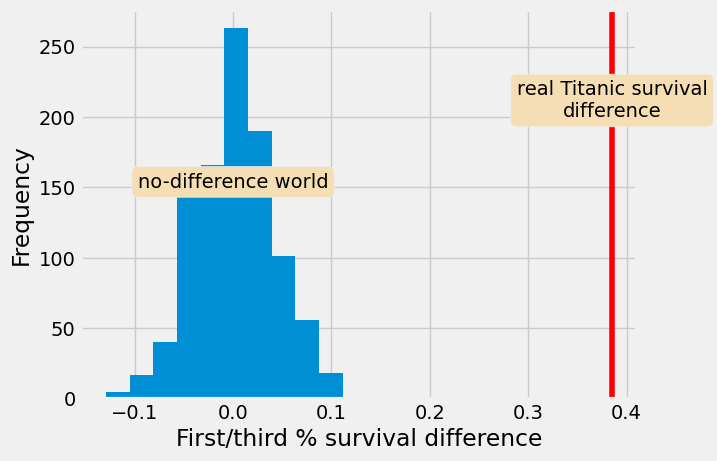

In [103]:
# plot a histogram (distribution) of simulated outcomes
plt.hist(sim_result)

# mark where the real world outcome is with a red line
plt.axvline(real_survival_difference,color="red")

# label parts of the plot
plt.xlabel("First/third % survival difference") # x axis label
plt.ylabel("Frequency") # y axis label

# set a textbox style and color
props = dict(boxstyle='round', facecolor='wheat')
# put a text box on the real value
plt.text(real_survival_difference,200,"real Titanic survival\ndifference",horizontalalignment="center",bbox=props)
# put a text box on the simulated values
plt.text(0,150,"no-difference world",horizontalalignment="center",bbox=props)

### The conventional statistical test would be chi-square

In [104]:
# we would use this table:

survival_1_3

Pclass,first,third
Survived,,
died,80,368
survived,136,119


In [105]:
stat, p, dof, expected = stats.chi2_contingency(survival_1_3)
print("Chi-square: ",np.round(stat,2)," p-value: ",p," df: ",dof)
print("Expected values:\n",expected)

Chi-square:  94.43  p-value:  2.5423203398081356e-22  df:  1
Expected values:
 [[137.65007112 310.34992888]
 [ 78.34992888 176.65007112]]


#### Notice that the p-value from the chi-square test is also very small

0.0000000000000000000000254

This value is essentially zero.  We would have to run **loads** of simulations to estimate a value this small.

### Exercise: Try a different world -- make sure you understand how to interpret this result
#### (run the cell below here and then go back to \*\* restart here \*\* and run the cells after that point to try with these data)

In [106]:
survival_1_3["first"] = [168, 48]
survival_1_3["third"] = [400, 87]
survival_1_3

Pclass,first,third
Survived,,
died,168,400
survived,48,87


### Do an analysis of one of the following real tables

**Treatment for epilepsy:** Did patients with a distinct focal lesion benefit from surgery more often than patients without a distinct focal lesion? (Bien et al., 2009) - see epilepsy.pdf

|                   | Seizure-Free | Continued Seizures |
|-------------------|--------------|--------------------|
|Distinct lesion    |            7 |                  2 |
|No distinct lesion |            4 |                 16 |


**Cognitive therapy for depression**  Can cognitive therapy be as effective as medication for treating depression? (DeRubeis et al., 2005) - see cognitive_therapy_for_depression.pdf

|                         | Remission | No Remission |
|-------------------------|-----------|--------------|
| Cognitive Therapy       |       24  |         36   |
| Medication (Paroxetine) |       55  |         65   |
